# 📊 Analyse Exploratoire et Nettoyage des Données — Uber NCR Ride Bookings

## Sommaire
1. **Configuration & Style Global**
2. **Nettoyage des Données & Audit Qualité (NaN, Types, Doublons)**
3. **Problématique 1 : Facteurs d'annulation (Statuts, Motifs, VTAT, Notes, Zones géographiques)**
4. **Problématique 2 : Performance des véhicules & Méthodes de paiement**
5. **Problématique 3 : Temporalité & Pics de demande (Mois, Jours, Heures)**
6. **Synthèse & Conclusions Métier**

---
## 1. Configuration et Style Global des Visualisations

Importation des bibliothèques nécessaires et définition de la charte graphique commune (`tab20b`, thème clair) appliquée à l'ensemble des graphiques du notebook.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

# ======================================================
# STYLE GLOBAL — THÈME CLAIR + PALETTE TAB20B
# ======================================================
TAB20B = plt.get_cmap("tab20b")

# Couleurs du thème
FIG_BG = "#E5E5E5"       # fond général
AXES_BG = "#DEDEDE"      # fond des graphiques
GRID = "#8A8A8A"         # grille
TEXT = "#333333"         # texte
BORDER = "#777777"       # bordures

# Couleurs issues de tab20b
COLOR_1 = TAB20B(0.10)
COLOR_2 = TAB20B(0.25)
COLOR_3 = TAB20B(0.40)
COLOR_4 = TAB20B(0.55)
COLOR_5 = TAB20B(0.70)
COLOR_6 = TAB20B(0.85)

# Couleurs fixes pour les classes de richesse
INCOME_COLORS = {
    "Poor": COLOR_1,
    "Middle": COLOR_3,
    "Rich": COLOR_5
}

# Palette générale
TAB20B_COLORS = [TAB20B(i / 19) for i in range(20)]

plt.style.use("default")
plt.rcParams["figure.facecolor"] = FIG_BG
plt.rcParams["axes.facecolor"] = AXES_BG
plt.rcParams["savefig.facecolor"] = FIG_BG
plt.rcParams["text.color"] = TEXT
plt.rcParams["axes.labelcolor"] = TEXT
plt.rcParams["xtick.color"] = TEXT
plt.rcParams["ytick.color"] = TEXT
plt.rcParams["axes.edgecolor"] = BORDER
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100

sns.set_palette(TAB20B_COLORS)


def uber_style(ax, title):
    """Applique la charte graphique uniforme à un axe Matplotlib."""
    ax.set_facecolor(AXES_BG)
    ax.set_title(title, fontsize=16, fontweight="bold", color=TEXT, pad=12)
    ax.tick_params(colors=TEXT, labelsize=9)

    for spine in ax.spines.values():
        spine.set_color(BORDER)
        spine.set_linewidth(0.8)

    ax.grid(color=GRID, linestyle="--", linewidth=0.5, alpha=0.35)
    ax.set_axisbelow(True)

    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)

    legend = ax.get_legend()
    if legend is not None:
        legend.get_frame().set_facecolor(FIG_BG)
        legend.get_frame().set_edgecolor(BORDER)
        for text in legend.get_texts():
            text.set_color(TEXT)

---
## 2. Nettoyage des Données et Audit Qualité

### 2.1 Pipeline de nettoyage et préparation des variables
Cette étape charge le fichier brut `ncr_ride_bookings.csv`, supprime d'éventuels doublons exacts, normalise les chaînes de caractères, vérifie la cohérence des valeurs numériques et crée les variables temporelles (`Month`, `Day`, `Hour`) et binaires (`Is_Cancelled`) utilisées dans toute la suite de l'analyse.

In [35]:
# ======================================================
# Chargement & Nettoyage
# ======================================================
df = pd.read_csv("data/ncr_ride_bookings.csv")

print("=" * 60)
print("AVANT NETTOYAGE")
print("=" * 60)
print(f"Lignes : {df.shape[0]}")
print(f"Colonnes : {df.shape[1]}")

# 1. Suppression des doublons
nb_doublons = df.duplicated().sum()
print(f"\nDoublons trouvés : {nb_doublons}")
df = df.drop_duplicates()

# 2. Nettoyage des colonnes texte
df.columns = df.columns.str.strip()
colonnes_texte = df.select_dtypes(include=["object", "string"]).columns.tolist()

for col in colonnes_texte:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .replace(["nan", "None", "NULL", "null", ""], np.nan)
    )

# 3. Conversion des variables temporelles et création des colonnes dérivées
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Month"] = df["Date"].dt.month_name()
df["Day"] = df["Date"].dt.day_name()
df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S", errors="coerce").dt.hour

# Indicateur global d'annulation (Client ou Chauffeur)
df["Is_Cancelled"] = df["Booking Status"].isin(["Cancelled by Customer", "Cancelled by Driver"])

# 4. Vérification des types
print("\nTypes des colonnes :")
print(df.dtypes)

# 5. Vérification des valeurs impossibles
print("\nVérification des valeurs impossibles :")
colonnes_numeriques = [
    "Booking Value", "Ride Distance", "Driver Ratings",
    "Customer Rating", "Avg VTAT", "Avg CTAT"
]

for col in colonnes_numeriques:
    if col in df.columns:
        negatif = (df[col] < 0).sum()
        print(f" - {col} : {negatif} valeur(s) négative(s)", end="")
        if "Rating" in col:
            hors_intervalle = ((df[col] < 0) | (df[col] > 5)).sum()
            print(f" | {hors_intervalle} hors intervalle [0, 5]")
        else:
            print()

# 6. Sauvegarde du dataset nettoyé
df.to_csv("data/ncr_ride_bookings_clean.csv", index=False)

print("\n" + "=" * 60)
print("NETTOYAGE TERMINÉ")
print("=" * 60)
print(f"Fichier sauvegardé : data/ncr_ride_bookings_clean.csv | Dimensions : {df.shape}")

AVANT NETTOYAGE
Lignes : 150000
Colonnes : 21

Doublons trouvés : 0

Types des colonnes :
Date                                 datetime64[us]
Time                                            str
Booking ID                                      str
Booking Status                                  str
Customer ID                                     str
Vehicle Type                                    str
Pickup Location                                 str
Drop Location                                   str
Avg VTAT                                    float64
Avg CTAT                                    float64
Cancelled Rides by Customer                 float64
Reason for cancelling by Customer               str
Cancelled Rides by Driver                   float64
Driver Cancellation Reason                      str
Incomplete Rides                            float64
Incomplete Rides Reason                         str
Booking Value                               float64
Ride Distance             

### 2.2 Visualisation et interprétation des valeurs manquantes (`NaN`)

**Observation technique :** `Avg VTAT` ne compte que 10 500 valeurs manquantes (7 %), car il est calculé automatiquement à partir des horodatages système dès qu'un chauffeur est assigné (l'horodatage associe une date et une heure précises à chaque événement informatique).

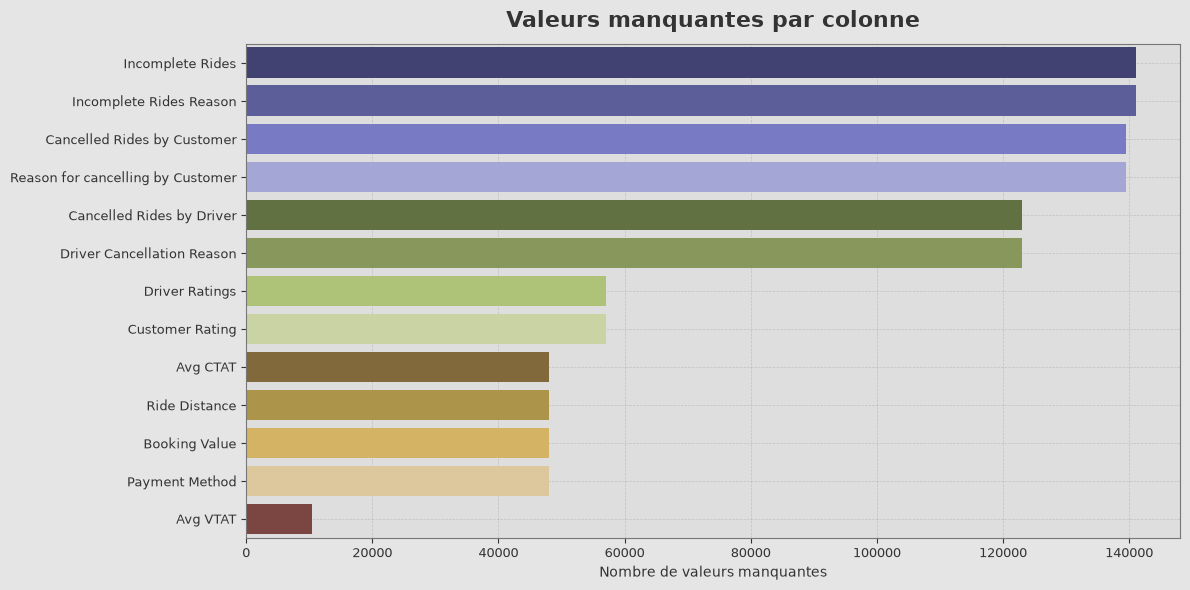

In [36]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=missing.values,
    y=missing.index,
    hue=missing.index,
    palette=TAB20B_COLORS[:len(missing)],
    legend=False,
    ax=ax
)

uber_style(ax, "Valeurs manquantes par colonne")

ax.set_xlabel("Nombre de valeurs manquantes")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


### 2.3 Rapport détaillé sur la structure et les valeurs manquantes

#### Structure du dataset
| Indicateur | Valeur |
|------------|-------:|
| Nombre de lignes | **150 000** |
| Nombre de colonnes | **21** (+ colonnes dérivées) |
| Doublons détectés | **0** |

#### Types de données vérifiés
* **Variables temporelles :** `Date` (`datetime`), `Time` (`HH:MM:SS`), `Month`, `Day`, `Hour`.
* **Variables quantitatives :** `Booking Value`, `Ride Distance`, `Driver Ratings`, `Customer Rating`, `Avg VTAT`, `Avg CTAT`.
* **Variables qualitatives :** `Vehicle Type`, `Booking Status`, `Payment Method`, `Pickup Location`, `Drop Location`, et les motifs d'annulation.

#### Justification métier des valeurs manquantes (`NaN`) par statut de réservation

1. **Cas 1 : `No Driver Found` (10 500 réservations — 7 %)**
   * *Variables manquantes :* `Booking Value`, `Ride Distance`, `Driver Ratings`, `Customer Rating`, `Payment Method`, `Avg VTAT`, `Avg CTAT` (10 500 `NaN`).
   * *Explication :* Aucun trajet n'a eu lieu, aucune distance parcourue ni paiement enregistré. **Ces `NaN` sont normaux et conservés.**
2. **Cas 2 : `Incomplete` (9 000 réservations — 6 %)**
   * *Variables manquantes :* `Driver Ratings` et `Customer Rating` (9 000 `NaN`), tandis que `Booking Value` et `Ride Distance` sont renseignés (0 `NaN`).
   * *Explication :* Le trajet a débuté mais a été interrompu avant son terme, empêchant l'évaluation mutuelle. **Ces `NaN` sont attendus.**
3. **Cas 3 : `Completed` (93 000 réservations — 62 %)**
   * *Variables manquantes :* `Cancelled Rides by Customer`, `Cancelled Rides by Driver`, `Incomplete Rides` (93 000 `NaN`).
   * *Explication :* La course s'étant déroulée normalement, les colonnes d'incident sont naturellement vides.
4. **Cas 4 : `Cancelled by Driver` (27 000 réservations — 18 %)**
   * *Variables manquantes :* `Booking Value`, `Ride Distance`, `Payment Method` (27 000 `NaN`), mais `Driver Cancellation Reason` est complet (0 `NaN`).
5. **Cas 5 : `Cancelled by Customer` (10 500 réservations — 7 %)**
   * *Variables manquantes :* `Booking Value`, `Ride Distance`, `Payment Method`, `Ratings` (10 500 `NaN`), mais `Reason for cancelling by Customer` est complet (0 `NaN`).

> **Synthèse du nettoyage :** Aucune ligne dupliquée ni valeur aberrante n'a été détectée. Les valeurs manquantes reflètent fidèlement le cycle de vie réel des réservations et ont été conservées intactes afin de ne pas biaiser les analyses.

---
## 3. Problématique 1 : Quels sont les facteurs qui influencent l'annulation d'une course ?

Nous analysons successivement :
* La répartition globale des statuts de réservation ;
* Les motifs déclarés par les clients et par les chauffeurs ;
* L'impact du temps d'attente (`Avg VTAT`) et du calendrier (jours/heures) ;
* Le rôle potentiel des notes (`Customer Rating` / `Driver Ratings`) ;
* L'influence géographique et socio-économique des zones de prise en charge (`Pickup Location`).

### 3.1 Répartition des statuts des courses
**Question :** Quel est le taux de réussite des réservations ?  
**Analyse :** 62 % des courses sont menées à terme (`Completed`), mais **25 % sont annulées** (18 % par les chauffeurs, 7 % par les clients), auxquelles s'ajoutent 7 % sans chauffeur trouvé et 6 % de trajets incomplets.

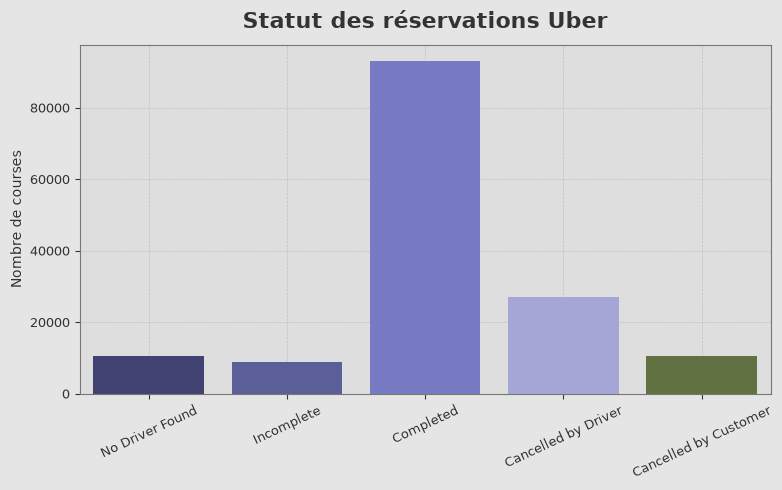

In [37]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Booking Status",
    hue="Booking Status",
    palette=TAB20B_COLORS[:df["Booking Status"].nunique()],
    legend=False
)

uber_style(ax, "Statut des réservations Uber")

plt.xticks(rotation=25)
plt.ylabel("Nombre de courses")
plt.xlabel("")

plt.tight_layout()
plt.show()


### 3.2 Motifs d'annulation côté clients
**Analyse :** Les principaux motifs permettent d'identifier les frictions liées à l'expérience utilisateur et au comportement des chauffeurs avant la prise en charge (*Driver is not moving towards pickup location*, *Driver asked to cancel*).

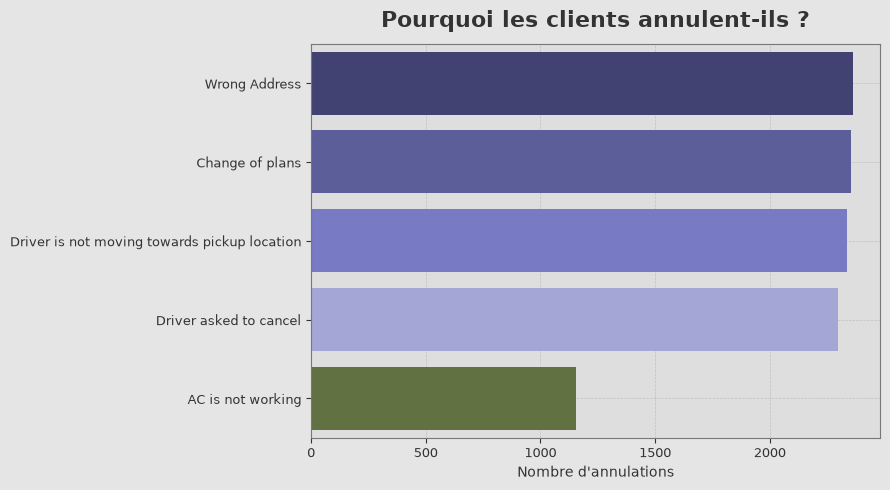

In [38]:
cancel_client = (
    df["Reason for cancelling by Customer"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=cancel_client.values,
    y=cancel_client.index,
    hue=cancel_client.index,
    palette=TAB20B_COLORS[:len(cancel_client)],
    legend=False
)

uber_style(ax, "Pourquoi les clients annulent-ils ?")

plt.xlabel("Nombre d'annulations")
plt.ylabel("")

plt.tight_layout()
plt.show()


### 3.3 Motifs d'annulation côté chauffeurs
**Analyse :** Les annulations chauffeurs représentent la première cause d'échec des réservations (27 000 courses).

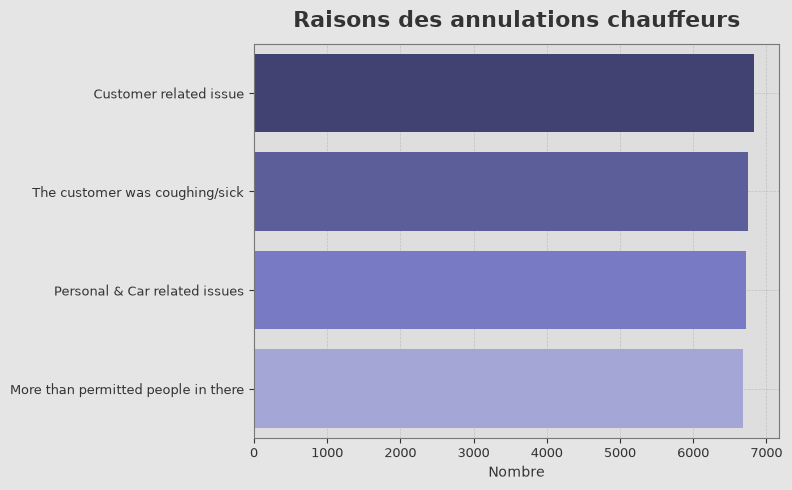

In [39]:
driver_cancel = (
    df["Driver Cancellation Reason"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=driver_cancel.values,
    y=driver_cancel.index,
    hue=driver_cancel.index,
    palette=TAB20B_COLORS[:len(driver_cancel)],
    legend=False
)

uber_style(ax, "Raisons des annulations chauffeurs")

plt.xlabel("Nombre")
plt.ylabel("")

plt.tight_layout()
plt.show()


### 3.4 Impact du temps d'attente (`Avg VTAT`) sur les annulations clients

**Analyse des résultats :**
* **Seuil critique des 12 minutes :** Le VTAT moyen pour les courses annulées par le client (`Cancelled by Customer`) est de **12,5 minutes**, contre **6,0 minutes** pour les courses incomplètes (`Incomplete`) — soit plus du double. Les usagers patientent environ un quart d'heure avant d'abandonner.
* **Courbe d'annulation par tranche de VTAT :** Le taux d'annulation client croît nettement à mesure que le temps d'approche du véhicule s'allonge.

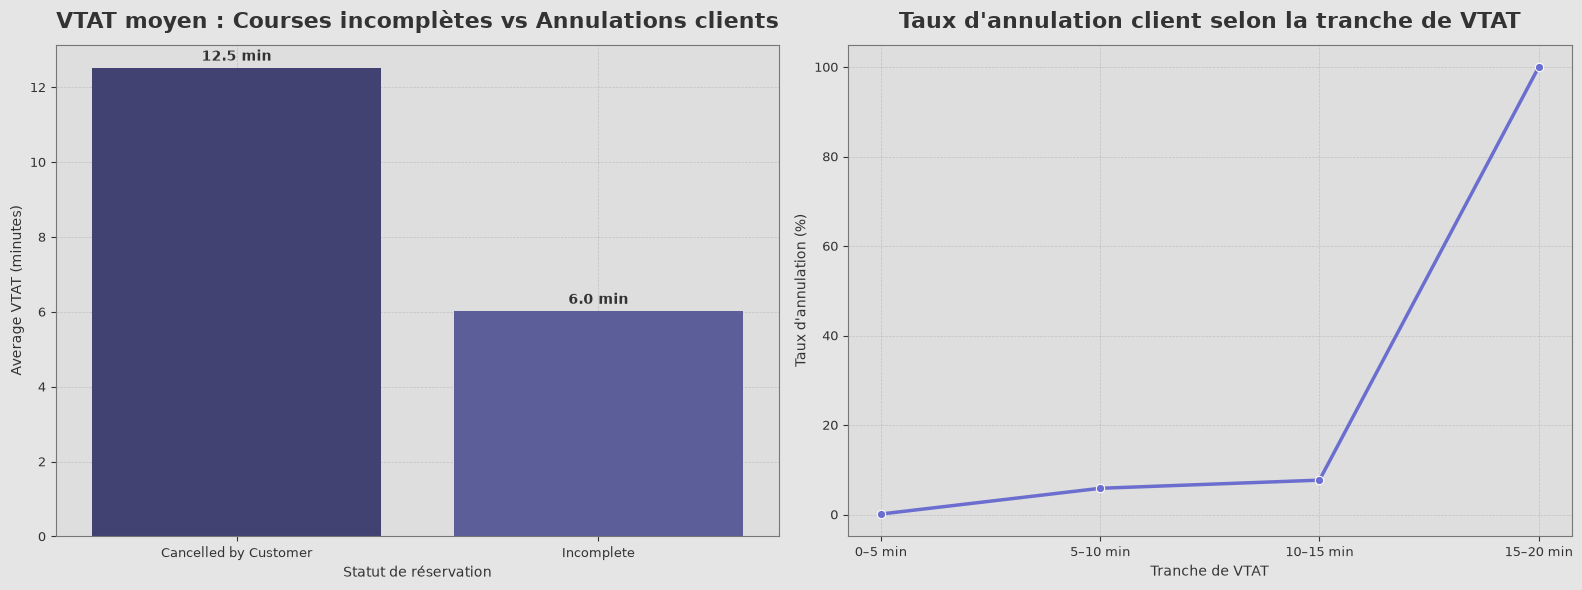

VTAT moyen - annulation client : 12.51 min
VTAT moyen - course incomplète : 6.01 min
Écart : 6.50 min (Ratio : 2.08x)


In [40]:
# 1. Comparaison VTAT moyen : Incomplete vs Cancelled by Customer
vtat_status = (
    df[df["Booking Status"].isin(["Incomplete", "Cancelled by Customer"])]
    .groupby("Booking Status")["Avg VTAT"]
    .mean()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique A : Barplot comparatif
sns.barplot(
    x=vtat_status.index,
    y=vtat_status.values,
    hue=vtat_status.index,
    palette=TAB20B_COLORS[:len(vtat_status)],
    legend=False,
    ax=axes[0]
)
uber_style(axes[0], "VTAT moyen : Courses incomplètes vs Annulations clients")
axes[0].set_xlabel("Statut de réservation")
axes[0].set_ylabel("Average VTAT (minutes)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f min", padding=3, color=TEXT, fontweight="bold")

# Graphique B : Taux d'annulation client par tranche de VTAT
bins = [0, 5, 10, 15, 20, float("inf")]
labels = ["0–5 min", "5–10 min", "10–15 min", "15–20 min", ">20 min"]
df["VTAT Bucket"] = pd.cut(df["Avg VTAT"], bins=bins, labels=labels, include_lowest=True)

vtat_cancel = (
    df.groupby("VTAT Bucket", observed=False)
      .agg(
          Courses=("Booking ID", "count"),
          Annulations=("Cancelled Rides by Customer", lambda x: x.notna().sum())
      )
)
vtat_cancel["Taux Annulation (%)"] = vtat_cancel["Annulations"] / vtat_cancel["Courses"] * 100

sns.lineplot(
    x=vtat_cancel.index.astype(str),
    y=vtat_cancel["Taux Annulation (%)"],
    marker="o",
    color=COLOR_1,
    linewidth=2.5,
    ax=axes[1]
)
uber_style(axes[1], "Taux d'annulation client selon la tranche de VTAT")
axes[1].set_xlabel("Tranche de VTAT")
axes[1].set_ylabel("Taux d'annulation (%)")

plt.tight_layout()
plt.show()

# Affichage des KPI VTAT
vtat_cancelled = df.loc[df["Booking Status"] == "Cancelled by Customer", "Avg VTAT"].mean()
vtat_incomplete = df.loc[df["Booking Status"] == "Incomplete", "Avg VTAT"].mean()
print(f"VTAT moyen - annulation client : {vtat_cancelled:.2f} min")
print(f"VTAT moyen - course incomplète : {vtat_incomplete:.2f} min")
print(f"Écart : {vtat_cancelled - vtat_incomplete:.2f} min (Ratio : {vtat_cancelled / vtat_incomplete:.2f}x)")

### 3.5 Éclairage métier : Pourquoi les VTAT et les annulations sont-ils si élevés à New Delhi (Delhi NCR) ?

Un **VTAT moyen de 12,5 minutes avant annulation** s'explique par quatre facteurs structurels, culturels et économiques propres au marché indien des VTC (**Uber**, **Ola**) :

1. **Le phénomène du « Caché-Négocié » (destination à l'aveugle) :**
   * Historiquement, le chauffeur ne voyait pas toujours la destination finale ni le mode de paiement avant d'accepter.
   * Il appelle systématiquement le client (*« Drop kahan hai ? Cash ou en ligne ? »*) et, si la course ne lui convient pas, refuse d'avancer pour forcer le client à annuler lui-même afin de préserver son propre taux d'acceptation/annulation.
2. **La préférence forte pour le paiement en espèces (`Cash`) :**
   * Besoin quotidien de liquidités (carburant GNC, frais de location) et volonté d'éviter les commissions et délais de versement liés aux paiements numériques.
3. **La congestion urbaine et les frontières inter-États (New Delhi, Noida, Gurugram) :**
   * Embouteillages imprévisibles rallongeant fortement l'approche réelle, et refus des trajets périphériques impliquant un retour à vide ou des taxes de passage d'État.
4. **La tolérance culturelle à l'attente et à la négociation :**
   * Habitués aux négociations avec les auto-rickshaws et taxis locaux, les clients patientent longtemps avant d'annuler.

| Facteur | Effet sur le VTAT |
|---|---|
| Destination cachée avant acceptation | Appels et négociations après acceptation |
| Préférence pour le cash | Refus des paiements numériques |
| Stratégie d'attente du chauffeur | Le client annule à la place du chauffeur |
| Embouteillages de Delhi NCR | Temps d'arrivée imprévisible |
| Refus de certaines zones | Courses abandonnées |
| Tolérance des clients | Annulations plus tardives |

### 3.6 Taux d'annulation client selon le jour de la semaine et l'heure

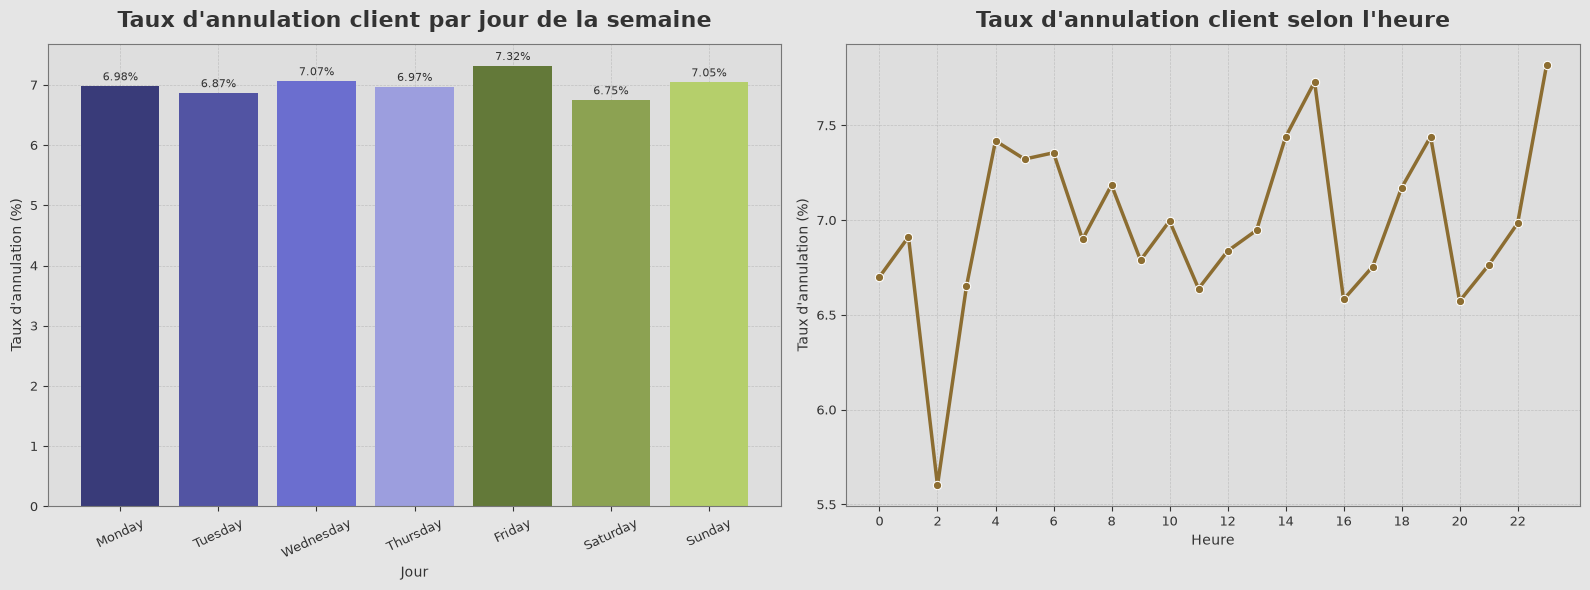

In [41]:
ordre_jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Par jour de la semaine
daily_cancel = (
    df.groupby("Day")
      .agg(
          Courses=("Booking ID", "count"),
          Annulations=("Booking Status", lambda x: (x == "Cancelled by Customer").sum())
      )
      .reindex(ordre_jours)
)
daily_cancel["Taux Annulation (%)"] = daily_cancel["Annulations"] / daily_cancel["Courses"] * 100

bars = axes[0].bar(daily_cancel.index, daily_cancel["Taux Annulation (%)"], color=TAB20B_COLORS[:7])
uber_style(axes[0], "Taux d'annulation client par jour de la semaine")
axes[0].set_xlabel("Jour")
axes[0].set_ylabel("Taux d'annulation (%)")
axes[0].tick_params(axis="x", rotation=25)
for bar, val in zip(bars, daily_cancel["Taux Annulation (%)"]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f"{val:.2f}%", ha="center", va="bottom", fontsize=8, color=TEXT)

# Par heure de la journée
hourly_cancel = (
    df.groupby("Hour")
      .agg(
          Courses=("Booking ID", "count"),
          Annulations=("Booking Status", lambda x: (x == "Cancelled by Customer").sum())
      )
)
hourly_cancel["Taux Annulation (%)"] = hourly_cancel["Annulations"] / hourly_cancel["Courses"] * 100

sns.lineplot(x=hourly_cancel.index, y=hourly_cancel["Taux Annulation (%)"], marker="o", color=COLOR_3, linewidth=2.5, ax=axes[1])
uber_style(axes[1], "Taux d'annulation client selon l'heure")
axes[1].set_xlabel("Heure")
axes[1].set_ylabel("Taux d'annulation (%)")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

### 3.7 Distribution des notes clients et chauffeurs (et biais de sélection)

**Observation :** Les notes clients (`Customer Rating`) et chauffeurs (`Driver Ratings`) sont fortement concentrées vers le haut de l'échelle (entre 4,0 et 5,0).

> ⚠️ **Attention au biais de sélection :**  
> Lorsqu'un chauffeur consulte la note d'un client et décide d'annuler parce qu'il la juge trop faible, **la course n'a pas lieu et aucune note n'est enregistrée dans le CSV**.  
> Les distributions ci-dessous ne reflètent donc que les **courses effectivement réalisées**. On ne peut pas conclure que les mauvaises notes n'influencent pas les annulations : les clients mal notés sont simplement censurés des observations finales.

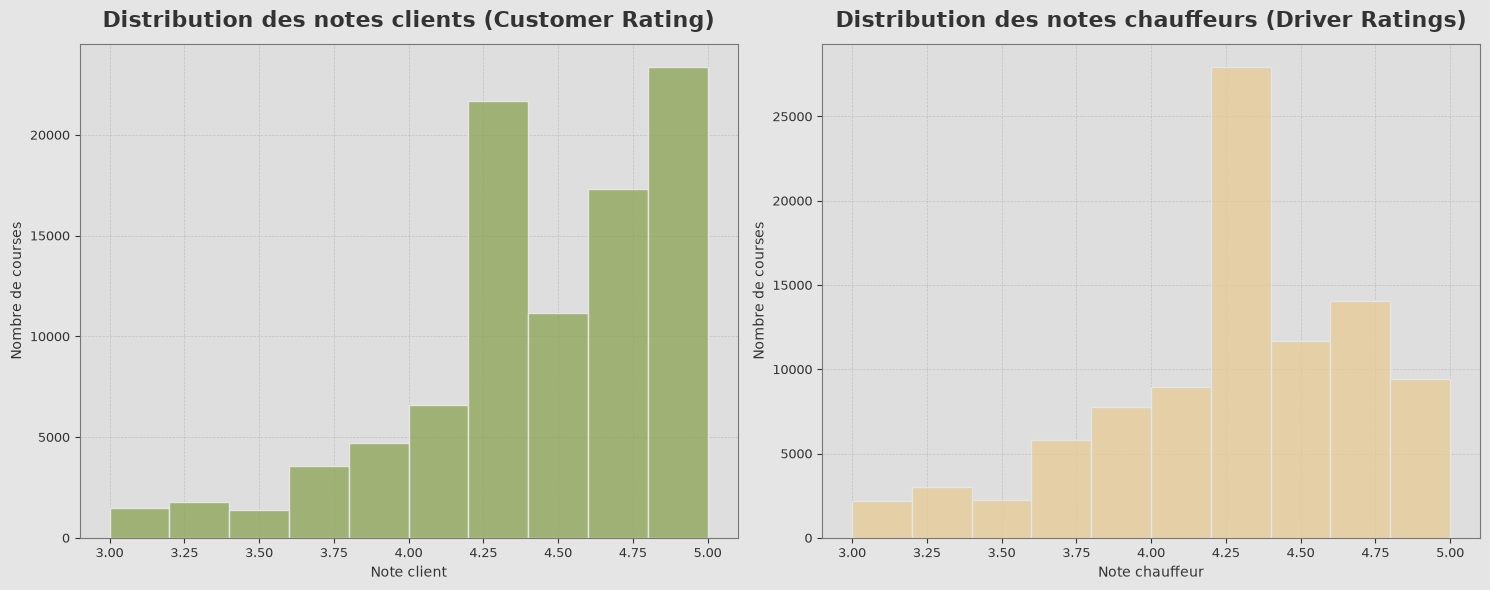

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.histplot(df["Customer Rating"], bins=10, color=COLOR_2, edgecolor=FIG_BG, ax=axes[0])
uber_style(axes[0], "Distribution des notes clients (Customer Rating)")
axes[0].set_xlabel("Note client")
axes[0].set_ylabel("Nombre de courses")

sns.histplot(df["Driver Ratings"], bins=10, color=COLOR_4, edgecolor=FIG_BG, ax=axes[1])
uber_style(axes[1], "Distribution des notes chauffeurs (Driver Ratings)")
axes[1].set_xlabel("Note chauffeur")
axes[1].set_ylabel("Nombre de courses")

plt.tight_layout()
plt.show()

### 3.8 Analyse géographique : Zones de prise en charge et niveau de richesse (`Income_Level`)

Nous croisons les 176 zones de départ (`Pickup Location`) avec leur classification socio-économique (`Poor`, `Middle`, `Rich` issues de `locations_gps.csv`) afin de vérifier si le niveau de richesse d'un quartier influence le taux d'annulation (sur l'ensemble des **150 000 courses**, en filtrant les zones comptant au moins 100 réservations).

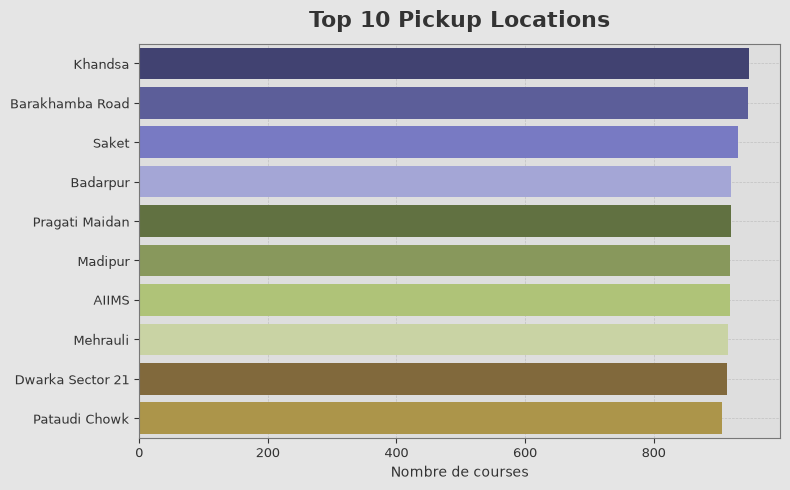

In [43]:
top10 = df["Pickup Location"].value_counts().head(10)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=top10.values,
    y=top10.index,
    hue=top10.index,
    palette=TAB20B_COLORS[:len(top10)],
    legend=False
)

uber_style(ax, "Top 10 Pickup Locations")

plt.xlabel("Nombre de courses")
plt.ylabel("")

plt.tight_layout()
plt.show()


C:\Users\PC\AppData\Local\Temp\ipykernel_14236\2649152854.py:42: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_geo.drop(columns=["Place"], inplace=True)


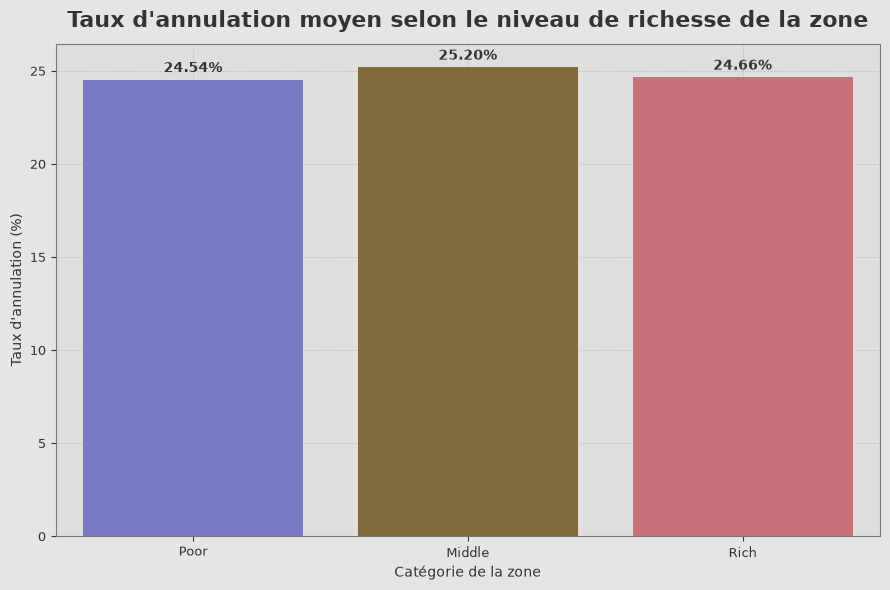

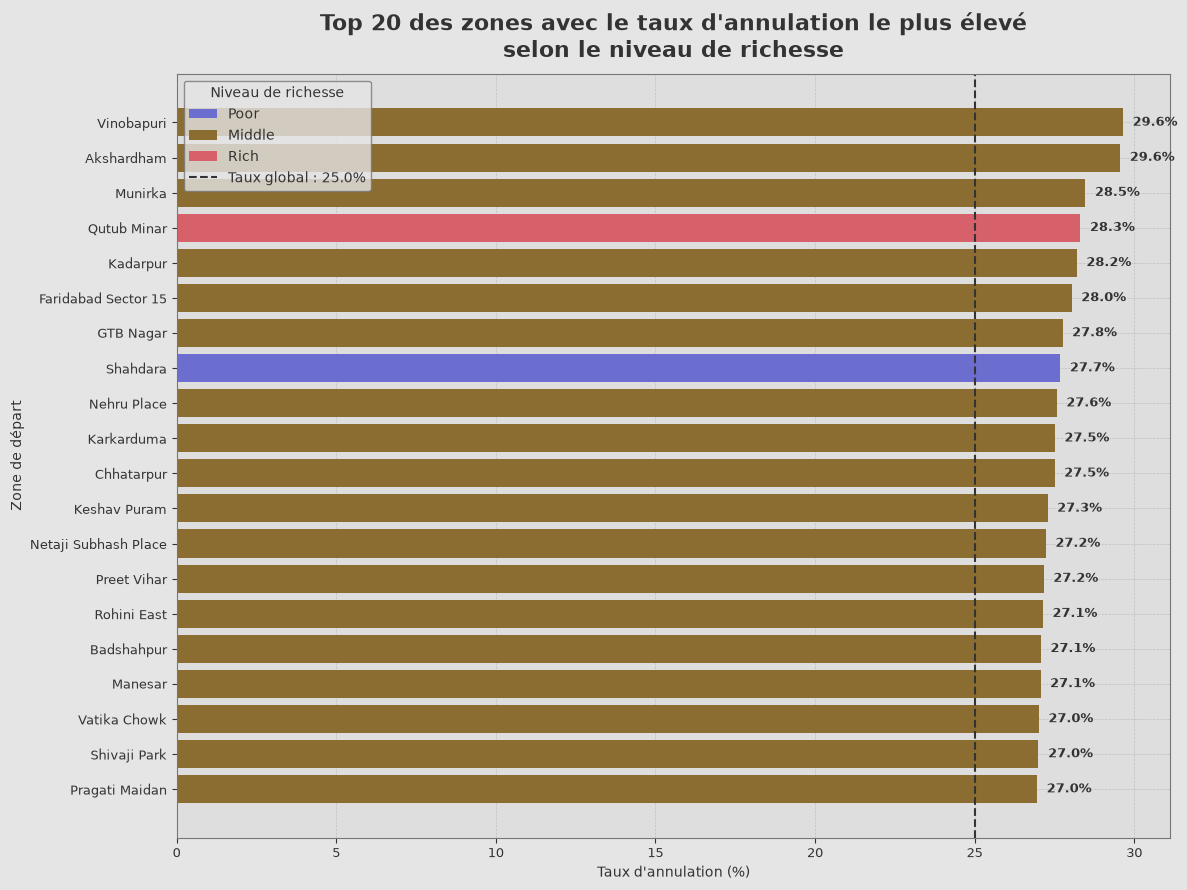

In [44]:
# ============================================================
# 1. CLASSIFICATION SOCIO-ÉCONOMIQUE DES ZONES (locations_gps.csv)
# ============================================================
locations = pd.read_csv("data/locations_gps.csv")

rich_zones = [
    "Palam Vihar", "Central Secretariat", "AIIMS", "Udyog Bhawan", "Vidhan Sabha",
    "Patel Chowk", "Pitampura", "Punjabi Bagh", "Noida Sector 18", "Cyber Hub",
    "Qutub Minar", "DLF City Court", "Civil Lines Gurgaon", "Rajiv Chowk", "MG Road",
    "Ardee City", "Lajpat Nagar", "Sushant Lok", "IIT Delhi", "Khan Market",
    "DLF Phase 3", "Huda City Centre", "India Gate", "Barakhamba Road",
    "Gurgaon Sector 56", "Gurgaon Sector 29", "Jor Bagh", "Saket", "Lok Kalyan Marg",
    "Greater Kailash", "South Extension", "Green Park", "Chanakyapuri", "RK Puram",
    "Vasant Kunj", "Hauz Khas", "Panchsheel Park", "Golf Course Road",
    "Bhikaji Cama Place", "Ambience Mall"
]

poor_zones = [
    "Khandsa", "Madipur", "Jama Masjid", "Okhla", "Sadar Bazar Gurgaon",
    "Shastri Park", "Mundka", "Seelampur", "Dilshad Garden", "Aya Nagar",
    "Tughlakabad", "Shahdara", "Welcome", "Jahangirpuri", "Govindpuri",
    "Badarpur", "Samaypur Badli", "Paharganj", "Gurgaon Railway Station",
    "Basai Dhankot", "Bhiwadi"
]

def classify_income(place):
    if place in rich_zones:
        return "Rich"
    elif place in poor_zones:
        return "Poor"
    return "Middle"

locations["Place"] = locations["Place"].astype(str).str.strip()
locations["Income_Level"] = locations["Place"].apply(classify_income)
locations.to_csv("data/locations_gps_income.csv", index=False, encoding="utf-8")

# ============================================================
# 2. FUSION AVEC LE DATASET COMPLET (150 000 COURSES)
# ============================================================
income_mapping = locations[["Place", "Income_Level"]].drop_duplicates("Place")
df_geo = df.merge(income_mapping, left_on="Pickup Location", right_on="Place", how="left")
df_geo.drop(columns=["Place"], inplace=True)
df_geo.to_csv("data/ncr_ride_bookings_with_income.csv", index=False, encoding="utf-8")

# ============================================================
# 3. TAUX D'ANNULATION MOYEN PAR NIVEAU DE RICHESSE
# ============================================================
avg_income = (
    df_geo.groupby("Income_Level")["Is_Cancelled"]
    .mean()
    .reindex(["Poor", "Middle", "Rich"])
    .reset_index()
)
avg_income["Cancellation Rate (%)"] = avg_income["Is_Cancelled"] * 100

fig, ax = plt.subplots(figsize=(9, 6))
bars = sns.barplot(
    data=avg_income,
    x="Income_Level",
    y="Cancellation Rate (%)",
    hue="Income_Level",
    palette=INCOME_COLORS,
    legend=False,
    ax=ax
)
uber_style(ax, "Taux d'annulation moyen selon le niveau de richesse de la zone")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_xlabel("Catégorie de la zone")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, color=TEXT, fontweight="bold")

plt.tight_layout()
plt.show()

# ============================================================
# 4. TOP 20 DES ZONES AVEC LE PLUS HAUT TAUX D'ANNULATION (>= 100 COURSES)
# ============================================================
zone_analysis = (
    df_geo.groupby(["Pickup Location", "Income_Level"], dropna=False)
    .agg(
        Nombre_Courses=("Is_Cancelled", "size"),
        Nombre_Annulees=("Is_Cancelled", "sum")
    )
    .reset_index()
)
zone_analysis["Taux_Annulation"] = zone_analysis["Nombre_Annulees"] / zone_analysis["Nombre_Courses"] * 100
zone_analysis = zone_analysis[zone_analysis["Nombre_Courses"] >= 100].copy()

global_rate = df_geo["Is_Cancelled"].mean() * 100
top20 = zone_analysis.sort_values("Taux_Annulation", ascending=False).head(20).sort_values("Taux_Annulation", ascending=True)

bar_colors = [INCOME_COLORS.get(level, COLOR_1) for level in top20["Income_Level"]]

fig, ax = plt.subplots(figsize=(12, 9))
bars = ax.barh(top20["Pickup Location"], top20["Taux_Annulation"], color=bar_colors)
uber_style(ax, "Top 20 des zones avec le taux d'annulation le plus élevé\nselon le niveau de richesse")

for bar, rate in zip(bars, top20["Taux_Annulation"]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, f"{rate:.1f}%", va="center", fontsize=9, color=TEXT, fontweight="bold")

ax.axvline(global_rate, color=TEXT, linestyle="--", linewidth=1.5)

legend_elements = [
    Patch(facecolor=INCOME_COLORS["Poor"], label="Poor"),
    Patch(facecolor=INCOME_COLORS["Middle"], label="Middle"),
    Patch(facecolor=INCOME_COLORS["Rich"], label="Rich"),
    Line2D([0], [0], color=TEXT, linestyle="--", linewidth=1.5, label=f"Taux global : {global_rate:.1f}%")
]
ax.legend(handles=legend_elements, title="Niveau de richesse", facecolor=FIG_BG, edgecolor=BORDER, labelcolor=TEXT, title_fontsize=10)
ax.set_xlabel("Taux d'annulation (%)")
ax.set_ylabel("Zone de départ")

plt.tight_layout()
plt.show()

---
## 4. Problématique 2 : Quels véhicules sont les plus utilisés et lesquels génèrent le plus de revenus ?

Nous étudions :
* La part de marché (volume de réservations) et la part de chiffre d'affaires (`Booking Value`) par type de véhicule ;
* La distance moyenne parcourue (`Ride Distance`) sur les courses complétées (`Completed`) ;
* La relation entre le montant de la course, la durée du trajet (`Avg CTAT`) et les évaluations ;
* La répartition des méthodes de paiement (`Payment Method`).

### 4.1 Popularité (nombre de courses) et revenus générés par type de véhicule

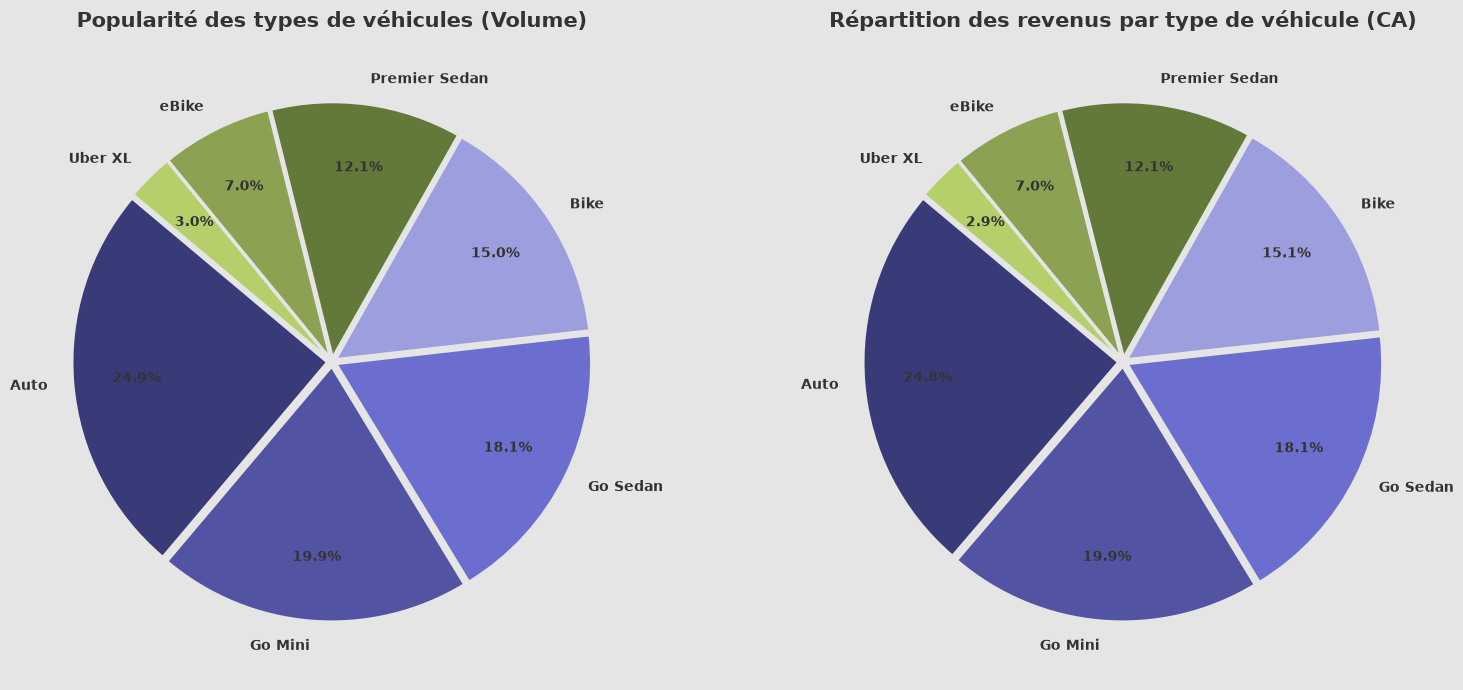

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Nombre de courses par véhicule
vehicle = df["Vehicle Type"].value_counts()
axes[0].pie(
    vehicle,
    labels=vehicle.index,
    colors=TAB20B_COLORS[:len(vehicle)],
    explode=[0.02] * len(vehicle),
    startangle=140,
    autopct="%1.1f%%",
    pctdistance=0.75,
    textprops={"color": TEXT, "fontsize": 10, "fontweight": "bold"},
    wedgeprops=dict(edgecolor=FIG_BG, linewidth=1.5)
)
axes[0].set_title("Popularité des types de véhicules (Volume)", color=TEXT, fontsize=15, fontweight="bold", pad=12)

# 2. Revenus par type de véhicule
revenue = df.groupby("Vehicle Type")["Booking Value"].sum().sort_values(ascending=False)
axes[1].pie(
    revenue,
    labels=revenue.index,
    colors=TAB20B_COLORS[:len(revenue)],
    explode=[0.02] * len(revenue),
    startangle=140,
    autopct="%1.1f%%",
    pctdistance=0.75,
    textprops={"color": TEXT, "fontsize": 10, "fontweight": "bold"},
    wedgeprops=dict(edgecolor=FIG_BG, linewidth=1.5)
)
axes[1].set_title("Répartition des revenus par type de véhicule (CA)", color=TEXT, fontsize=15, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

### 4.2 Distance moyenne parcourue par type de véhicule (courses `Completed`)

Statistiques sur échantillon équilibré :
               Nombre_de_trajets  Distance_moyenne  Ecart_type
Vehicle Type                                                  
Auto                        2783             25.90       13.86
Bike                        2783             26.52       13.68
Go Mini                     2783             26.05       13.86
Go Sedan                    2783             26.18       13.86
Premier Sedan               2783             25.85       13.69
Uber XL                     2783             25.72       13.78
eBike                       2783             26.31       13.80


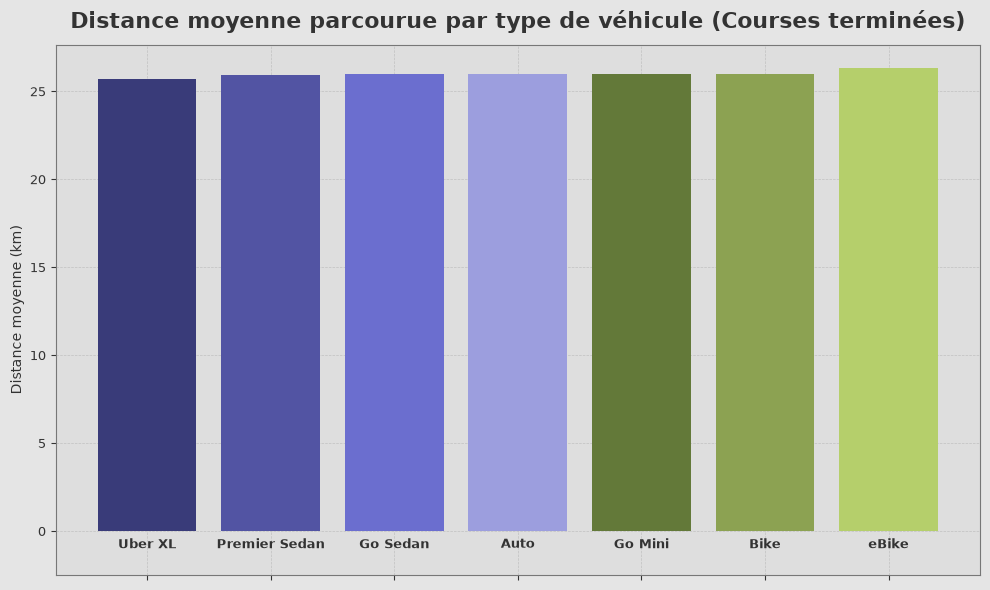

In [46]:
# Filtrage sur les trajets terminés sans écraser le DataFrame principal df
df_completed = df[df["Booking Status"] == "Completed"].copy()

# Vérification sur échantillon équilibré
n_min = df_completed["Vehicle Type"].value_counts().min()
df_equilibre = df_completed.groupby("Vehicle Type", group_keys=False).sample(n=n_min, random_state=42)
stats_dist = (
    df_equilibre.groupby("Vehicle Type")["Ride Distance"]
    .agg(Nombre_de_trajets="count", Distance_moyenne="mean", Ecart_type="std")
    .round(2)
)
print("Statistiques sur échantillon équilibré :")
print(stats_dist)

# Graphique sur l'ensemble des trajets complétés
distance_moyenne = df_completed.groupby("Vehicle Type")["Ride Distance"].mean().sort_values()

images = {
    "Auto": "images/Auto.jpg",
    "eBike": "images/eBike.jpg",
    "Go Mini": "images/GoMini.jpg",
    "Go Sedan": "images/GoSedan.jpg",
    "Uber XL": "images/UberXL.jpg",
    "Premier Sedan": "images/Premier Sedan.jpg",
    "Bike": "images/eBike.jpg"
}

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(range(len(distance_moyenne)), distance_moyenne.values, color=TAB20B_COLORS[:len(distance_moyenne)])
uber_style(ax, "Distance moyenne parcourue par type de véhicule (Courses terminées)")
ax.set_ylabel("Distance moyenne (km)")
ax.set_xticks(range(len(distance_moyenne)))
ax.set_xticklabels([])

for i, vehicule in enumerate(distance_moyenne.index):
    try:
        img = mpimg.imread(images[vehicule])
        imagebox = OffsetImage(img, zoom=0.12)
        ab = AnnotationBbox(imagebox, (i, 0), xybox=(0, -45), xycoords="data", boxcoords="offset points", frameon=False)
        ax.add_artist(ab)
    except Exception:
        pass
    ax.text(i, -0.4, vehicule, ha="center", va="top", fontsize=9, color=TEXT, fontweight="bold")

ax.set_ylim(bottom=-2.5)
plt.tight_layout()
plt.show()

### 4.3 Relations croisées : Prix / Note chauffeur & Distance / Durée du trajet (`Avg CTAT`)

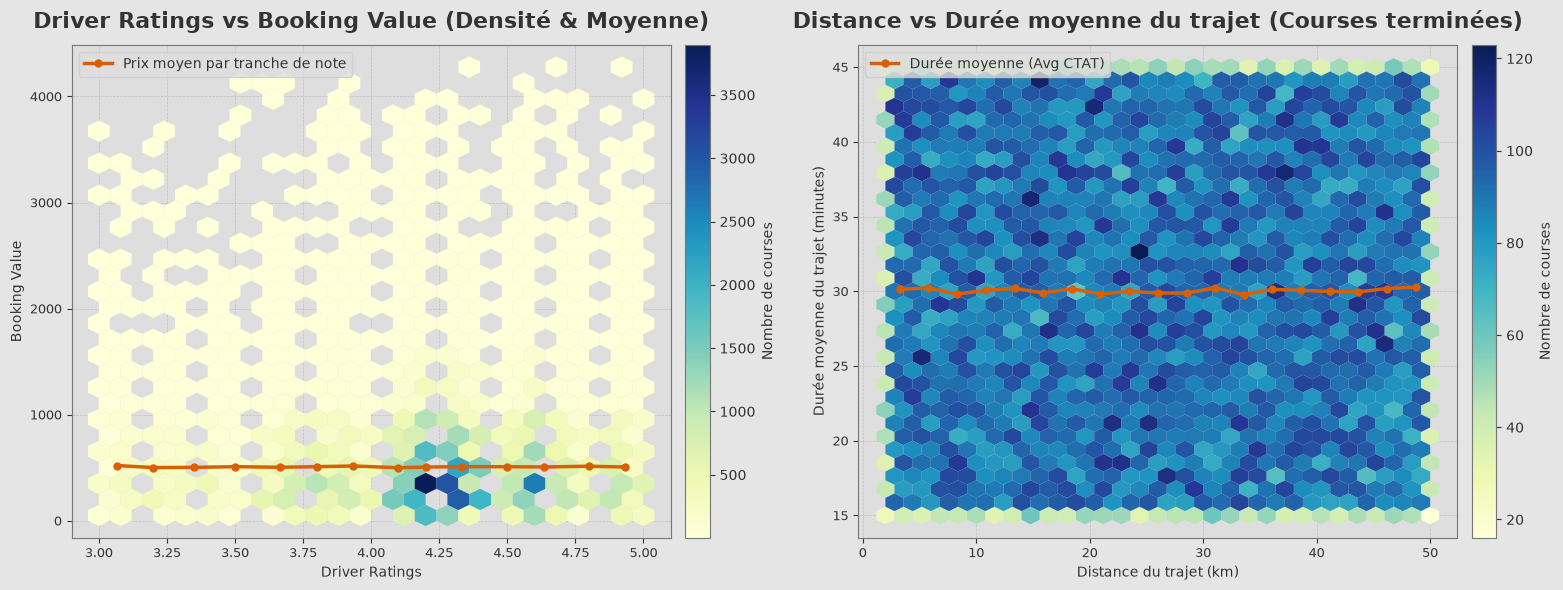

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Driver Ratings vs Booking Value (Hexbin / densité 2D pour éviter l'écrasement des 93 000 points)
valid_rv = df.dropna(subset=["Driver Ratings", "Booking Value"])
hb1 = axes[0].hexbin(
    valid_rv["Driver Ratings"],
    valid_rv["Booking Value"],
    gridsize=25,
    cmap="YlGnBu",
    mincnt=1,
    edgecolors="none"
)
cb1 = fig.colorbar(hb1, ax=axes[0], pad=0.02)
cb1.set_label("Nombre de courses", color=TEXT)
cb1.ax.yaxis.set_tick_params(color=TEXT)
plt.setp(plt.getp(cb1.ax.axes, "yticklabels"), color=TEXT)

# Moyenne mobile / par tranche de note pour rendre la tendance immédiatement visible
bins_rating = np.linspace(valid_rv["Driver Ratings"].min(), valid_rv["Driver Ratings"].max(), 15)
valid_rv = valid_rv.copy()
valid_rv["rating_bin"] = pd.cut(valid_rv["Driver Ratings"], bins=bins_rating, include_lowest=True)
mean_by_rating = valid_rv.groupby("rating_bin", observed=False).agg(
    x=("Driver Ratings", "mean"),
    y=("Booking Value", "mean")
).dropna()
axes[0].plot(
    mean_by_rating["x"],
    mean_by_rating["y"],
    color="#D95F02",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Prix moyen par tranche de note"
)
uber_style(axes[0], "Driver Ratings vs Booking Value (Densité & Moyenne)")
axes[0].set_xlabel("Driver Ratings")
axes[0].set_ylabel("Booking Value")
axes[0].legend(loc="upper left")

# 2. Distance vs Durée moyenne du trajet (Avg CTAT) sur courses terminées
valid_dc = df_completed.dropna(subset=["Ride Distance", "Avg CTAT"]).copy()
hb2 = axes[1].hexbin(
    valid_dc["Ride Distance"],
    valid_dc["Avg CTAT"],
    gridsize=30,
    cmap="YlGnBu",
    mincnt=1,
    edgecolors="none"
)
cb2 = fig.colorbar(hb2, ax=axes[1], pad=0.02)
cb2.set_label("Nombre de courses", color=TEXT)
cb2.ax.yaxis.set_tick_params(color=TEXT)
plt.setp(plt.getp(cb2.ax.axes, "yticklabels"), color=TEXT)

# Courbe de tendance moyenne par tranche de distance
bins_dist = np.linspace(valid_dc["Ride Distance"].min(), valid_dc["Ride Distance"].max(), 20)
valid_dc["dist_bin"] = pd.cut(valid_dc["Ride Distance"], bins=bins_dist, include_lowest=True)
mean_by_dist = valid_dc.groupby("dist_bin", observed=False).agg(
    x=("Ride Distance", "mean"),
    y=("Avg CTAT", "mean")
).dropna()
axes[1].plot(
    mean_by_dist["x"],
    mean_by_dist["y"],
    color="#D95F02",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Durée moyenne (Avg CTAT)"
)
uber_style(axes[1], "Distance vs Durée moyenne du trajet (Courses terminées)")
axes[1].set_xlabel("Distance du trajet (km)")
axes[1].set_ylabel("Durée moyenne du trajet (minutes)")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()


### 4.4 Classement des méthodes de paiement

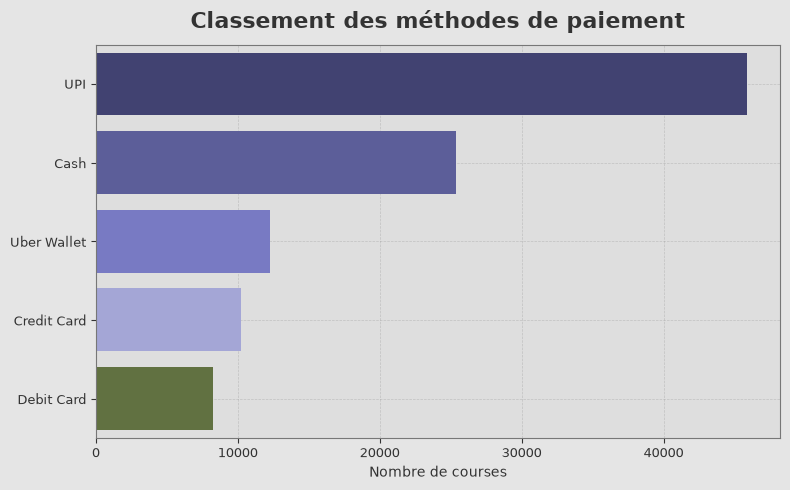

In [48]:
TopPayment = df["Payment Method"].value_counts()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=TopPayment.values,
    y=TopPayment.index,
    hue=TopPayment.index,
    palette=TAB20B_COLORS[:len(TopPayment)],
    legend=False
)

uber_style(ax, "Classement des méthodes de paiement")

plt.xlabel("Nombre de courses")
plt.ylabel("")

plt.tight_layout()
plt.show()


---
## 5. Problématique 3 : Quand la demande de trajets est-elle la plus forte ?

Nous analysons la saisonnalité et les rythmes d'activité à trois échelles temporelles :
* **Mensuelle :** Évolution du volume de réservations sur l'année ;
* **Horaire :** Identification des heures de pointe quotidiennes ;
* **Croisée (Jour × Heure) :** Carte thermique (`Heatmap`) combinant le jour de la semaine et l'heure de la journée.

### 5.1 Évolution mensuelle et horaire des réservations

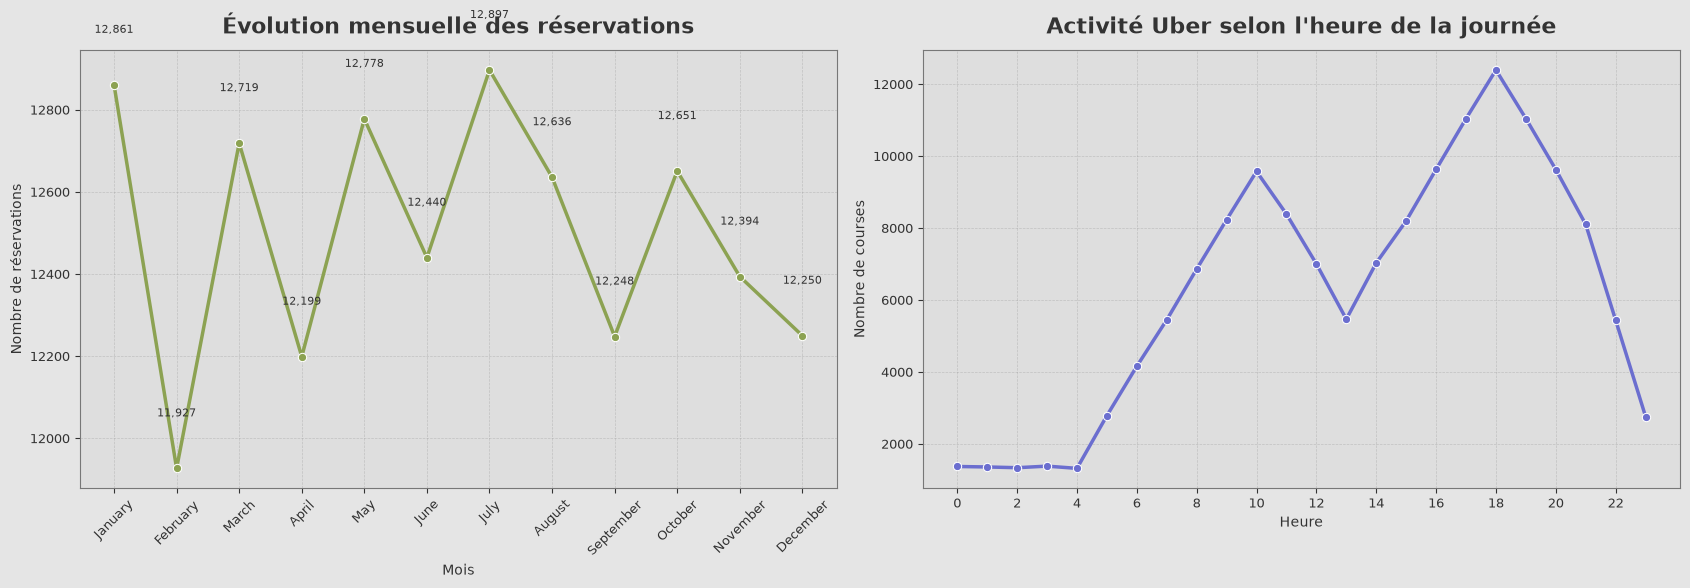

In [49]:
ordre_mois = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# 1. Évolution mensuelle
monthly = df.groupby("Month").size().reindex(ordre_mois)
sns.lineplot(x=monthly.index, y=monthly.values, marker="o", color=COLOR_2, linewidth=2.5, ax=axes[0])
uber_style(axes[0], "Évolution mensuelle des réservations")
for x, y in zip(monthly.index, monthly.values):
    axes[0].text(x, y + 120, f"{y:,}", ha="center", va="bottom", fontsize=8, color=TEXT)
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Nombre de réservations")
axes[0].set_xlabel("Mois")

# 2. Heures de pointe
hourly_counts = df["Hour"].value_counts().sort_index()
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker="o", color=COLOR_1, linewidth=2.5, ax=axes[1])
uber_style(axes[1], "Activité Uber selon l'heure de la journée")
axes[1].set_xlabel("Heure")
axes[1].set_ylabel("Nombre de courses")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

### 5.2 Carte thermique des réservations (Jour de la semaine × Heure)

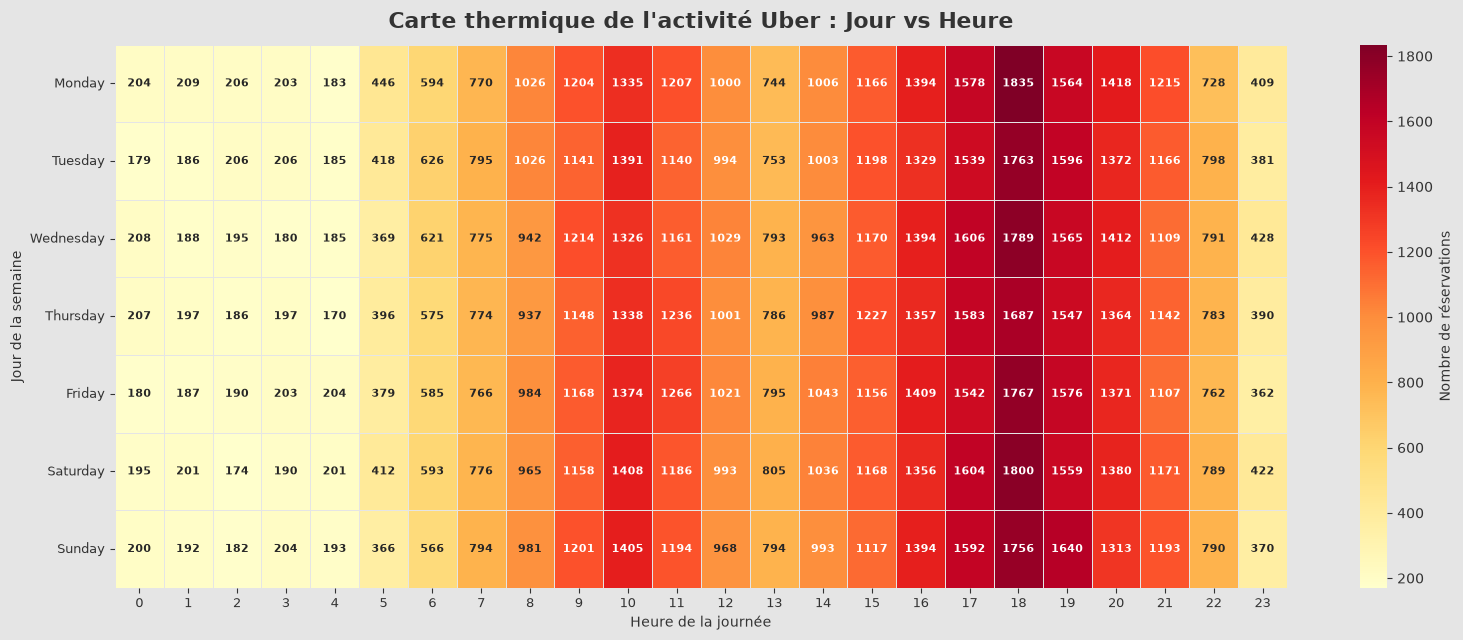

In [50]:
ordre_jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

pivot = pd.crosstab(df["Day"], df["Hour"]).reindex(ordre_jours)

plt.figure(figsize=(16, 6.5))
ax = sns.heatmap(
    pivot,
    cmap="YlOrRd",
    annot=True,
    fmt="d",
    annot_kws={"size": 8, "weight": "bold"},
    linewidths=0.6,
    linecolor=FIG_BG,
    cbar_kws={"label": "Nombre de réservations"}
)
uber_style(ax, "Carte thermique de l'activité Uber : Jour vs Heure")
ax.grid(False)
plt.xlabel("Heure de la journée")
plt.ylabel("Jour de la semaine")

cbar = ax.collections[0].colorbar
cbar.ax.yaxis.label.set_color(TEXT)
cbar.ax.tick_params(colors=TEXT)

plt.tight_layout()
plt.show()


---
## 6. Synthèse Générale des Enseignements

* **Qualité des données :** Le jeu de données (`150 000` réservations, `21` variables) est sain, sans doublons ni valeurs aberrantes. Les valeurs manquantes suivent strictement la logique métier des statuts de course.
* **Facteurs d'annulation (Problématique 1) :**
  * **38 % des demandes n'aboutissent pas** (18 % annulées par les chauffeurs, 7 % par les clients, 7 % sans chauffeur trouvé, 6 % incomplètes).
  * Le **temps d'attente (`Avg VTAT`)** est déterminant : les annulations clients surviennent après **12,5 min** en moyenne (plus du double des trajets interrompus).
  * Le contexte local de **Delhi NCR** (négociation du paiement en espèces, destination cachée, congestion) amplifie ce phénomène.
* **Véhicules & Revenus (Problématique 2) :**
  * Les catégories `Auto`, `Go Mini` et `Go Sedan` dominent à la fois en volume et en chiffre d'affaires généré.
  * Les paiements via **UPI** et **Cash** arrivent largement en tête des préférences utilisateurs.
* **Temporalité de la demande (Problématique 3) :**
  * L'activité est régulière tout au long de l'année mais présente des pics horaires marqués aux heures de trajets domicile-travail (matin et fin d'après-midi / soirée).